# Lỗ hổng đang bị khai thác nhưng có điểm CVSS thấp

**Câu hỏi:** trong các lỗ hổng đã được CISA xác nhận bị khai thác thực tế (danh mục KEV), có bao nhiêu lỗ hổng có điểm CVSS dưới 7,0?

Nếu tỷ lệ này đáng kể, thì một quy tắc ưu tiên vá chỉ dựa trên ngưỡng CVSS, như khuyến nghị vá trong 48 giờ cho lỗ hổng từ 8,0 điểm của Cloud Security Alliance, sẽ bỏ sót những lỗ hổng đang thực sự bị tấn công.

**Dữ liệu** (công khai, miễn phí):
- Điểm CVSS của mọi lỗ hổng: tệp dữ liệu theo năm của NVD (NIST).
- Danh mục KEV: kho dữ liệu chính thức của CISA trên GitHub.

**Cách chạy trên Google Colab:** mở notebook, chọn *Runtime, Run all*. Lần đầu mất vài phút để tải khoảng 300 MB dữ liệu NVD.

## 1. Cấu hình

In [1]:
import os, io, json, gzip, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START_YEAR = 2002      # tep 2002 cua NVD chua ca cac lo hong tu 1999 den 2002
END_YEAR   = 2025      # chi lay cac nam da tron ven
CVSS_NGUONG = 7.0      # nguong de xem xet
DATA_DIR = "du_lieu_nvd"
os.makedirs(DATA_DIR, exist_ok=True)

NVD_FEED = "https://nvd.nist.gov/feeds/json/cve/2.0/nvdcve-2.0-{y}.json.gz"
KEV_URL  = "https://raw.githubusercontent.com/cisagov/kev-data/develop/known_exploited_vulnerabilities.json"
UA = {"User-Agent": "Nhom14-course-research"}

def tai(url, path=None):
    """Tai mot tep, neu da co tren may thi dung lai."""
    if path and os.path.exists(path):
        return open(path, "rb").read()
    data = urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=300).read()
    if path:
        open(path, "wb").write(data)
    return data

## 2. Tải danh mục KEV

Danh mục các lỗ hổng mà CISA đã xác nhận đang bị khai thác thực tế, kèm ngày được đưa vào danh mục.

In [2]:
kev_js = json.loads(tai(KEV_URL, os.path.join(DATA_DIR, "kev.json")))
kev = pd.DataFrame(kev_js["vulnerabilities"])
kev["cveID"] = kev["cveID"].str.upper()
print(f"Phien ban danh muc KEV: {kev_js.get('catalogVersion')}, ngay phat hanh {kev_js.get('dateReleased', '')[:10]}")
print(f"So lo hong trong KEV: {len(kev):,}")
kev[["cveID", "vendorProject", "product", "dateAdded"]].head()

Phien ban danh muc KEV: 2026.10.08, ngay phat hanh 2026-10-08
So lo hong trong KEV: 1,739


,cveID,vendorProject,product,dateAdded
0,CVE-2015-5477,ISC,BIND,2026-10-08
1,CVE-2016-3081,Apache,Struts,2026-10-08
2,CVE-2023-22894,Strapi,Strapi,2026-10-08
3,CVE-2021-3199,ONLYOFFICE,Docs,2026-10-08
4,CVE-2015-3306,ProFTPD,ProFTPD,2026-10-08


## 3. Tải và đọc điểm CVSS của mọi lỗ hổng

Với mỗi lỗ hổng, lấy điểm **CVSS 3.x** nếu có. Lỗ hổng cũ chỉ có **CVSS 2.0** thì dùng điểm 2.0. Khi có nhiều điểm, ưu tiên điểm do NVD chấm, nếu không có thì dùng điểm do đơn vị công bố chấm. Lỗ hổng bị hủy (Rejected) được loại.

In [3]:
def chon(ds):
    """Uu tien diem do NVD cham (Primary), neu khong co thi lay diem cua don vi cong bo."""
    if not ds:
        return None
    for m in ds:
        if m.get("type") == "Primary":
            return m
    return ds[0]

rows = []
for y in range(START_YEAR, END_YEAR + 1):
    raw = tai(NVD_FEED.format(y=y), os.path.join(DATA_DIR, f"nvdcve-2.0-{y}.json.gz"))
    js = json.loads(gzip.decompress(raw))
    for it in js["vulnerabilities"]:
        c = it["cve"]
        if c.get("vulnStatus") == "Rejected":
            continue
        met = c.get("metrics", {})
        v3 = chon(met.get("cvssMetricV31")) or chon(met.get("cvssMetricV30"))
        v2 = chon(met.get("cvssMetricV2"))
        rows.append({
            "cve": c["id"].upper(),
            "nam": int(c["id"].split("-")[1]),
            "cvss3": v3["cvssData"]["baseScore"] if v3 else np.nan,
            "cvss2": v2["cvssData"]["baseScore"] if v2 else np.nan,
        })
    print(f"Da doc nam {y}: tong {len(rows):,} lo hong")

df = pd.DataFrame(rows).drop_duplicates("cve")
df["cvss"] = df["cvss3"].fillna(df["cvss2"])
df["phien_ban"] = np.where(df["cvss3"].notna(), "3.x", np.where(df["cvss2"].notna(), "2.0", "khong co"))
df = df[df["nam"] <= END_YEAR]
df["kev"] = df["cve"].isin(set(kev["cveID"]))
print(f"\nTong so lo hong: {len(df):,}, trong do co diem CVSS: {df['cvss'].notna().sum():,}")
df["phien_ban"].value_counts()

Da doc nam 2002: tong 6,670 lo hong


Da doc nam 2003: tong 8,174 lo hong


Da doc nam 2004: tong 10,818 lo hong


Da doc nam 2005: tong 15,445 lo hong


Da doc nam 2006: tong 22,440 lo hong


...

Da doc nam 2023: tong 234,327 lo hong


Da doc nam 2024: tong 272,798 lo hong


Da doc nam 2025: tong 316,367 lo hong



Tong so lo hong: 316,367, trong do co diem CVSS: 312,814


phien_ban
3.x         240409
2.0          72405
khong co      3553
Name: count, dtype: int64

## 4. Bao nhiêu lỗ hổng trong KEV có CVSS dưới 7,0

In [4]:
k = df[df["kev"] & df["cvss"].notna()]
thap = k[k["cvss"] < CVSS_NGUONG]
print(f"Lo hong KEV co diem CVSS:            {len(k):,}")
print(f"Trong do CVSS duoi {CVSS_NGUONG}:              {len(thap):,}  ({100*len(thap)/len(k):.1f}%)")
print(f"Trong do CVSS duoi 8.0 (nguong CSA): {(k['cvss'] < 8).sum():,}  ({100*(k['cvss'] < 8).mean():.1f}%)")

k3 = k[k["phien_ban"] == "3.x"]
print(f"\nChi tinh lo hong co CVSS 3.x: {len(k3):,} lo hong KEV, "
      f"duoi {CVSS_NGUONG}: {(k3['cvss'] < CVSS_NGUONG).sum():,} ({100*(k3['cvss'] < CVSS_NGUONG).mean():.1f}%)")

print("\nTy le lo hong KEV theo khoang diem CVSS:")
bins = [0, 4, 7, 9, 10.01]
labels = ["duoi 4.0", "4.0 den 6.9", "7.0 den 8.9", "9.0 den 10"]
print(pd.cut(k["cvss"], bins=bins, labels=labels, right=False).value_counts().reindex(labels).to_frame("so luong")
      .assign(ty_le=lambda t: (100 * t["so luong"] / t["so luong"].sum()).round(1).astype(str) + "%"))

Lo hong KEV co diem CVSS:            1,570
Trong do CVSS duoi 7.0:              179  (11.4%)
Trong do CVSS duoi 8.0 (nguong CSA): 693  (44.1%)

Chi tinh lo hong co CVSS 3.x: 1,570 lo hong KEV, duoi 7.0: 179 (11.4%)

Ty le lo hong KEV theo khoang diem CVSS:
             so luong  ty_le
cvss                        
duoi 4.0            5   0.3%
4.0 den 6.9       174  11.1%
7.0 den 8.9       857  54.6%
9.0 den 10        534  34.0%


## 5. Biểu đồ phân bố lỗ hổng theo năm và điểm CVSS

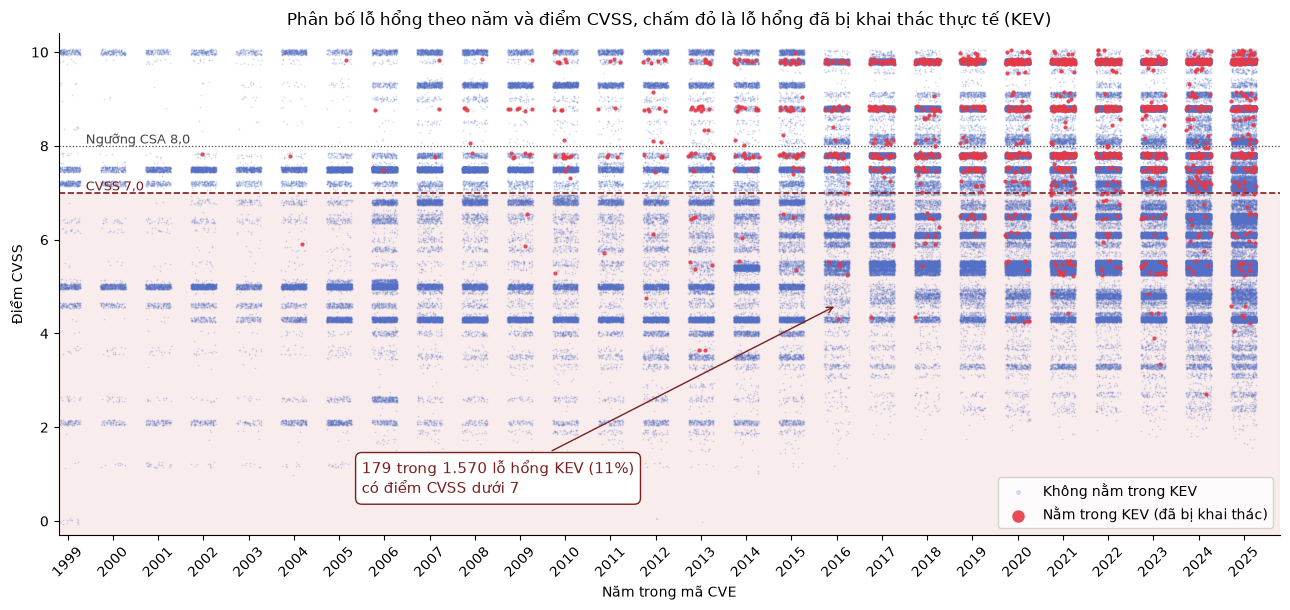

In [5]:
rng = np.random.default_rng(42)
d = df[df["cvss"].notna()].copy()
d["x"] = d["nam"] + rng.uniform(-0.28, 0.28, len(d))
d["y"] = d["cvss"] + rng.uniform(-0.06, 0.06, len(d))
xanh, do = d[~d["kev"]], d[d["kev"]]

fig, ax = plt.subplots(figsize=(13, 6.2))
ax.axhspan(-0.3, CVSS_NGUONG, color="#f2d7d5", alpha=0.45, zorder=0)
ax.scatter(xanh["x"], xanh["y"], s=1.5, c="#5470c6", alpha=0.25, lw=0, rasterized=True,
           label="Không nằm trong KEV", zorder=1)
ax.scatter(do["x"], do["y"], s=9, c="#e63946", alpha=0.9, lw=0, label="Nằm trong KEV (đã bị khai thác)", zorder=3)
ax.axhline(CVSS_NGUONG, color="#7a1f1f", lw=1.2, ls="--", zorder=2)
ax.axhline(8.0, color="#444", lw=0.9, ls=":", zorder=2)
ax.text(START_YEAR - 2.6, 8.05, "Ngưỡng CSA 8,0", fontsize=9, color="#444")
ax.text(START_YEAR - 2.6, CVSS_NGUONG + 0.05, "CVSS 7,0", fontsize=9, color="#7a1f1f")
ax.annotate(f"{len(thap)} trong {len(k):,} lỗ hổng KEV ({100*len(thap)/len(k):.0f}%)\n"
            f"có điểm CVSS dưới {CVSS_NGUONG:.0f}".replace(",", "."),
            xy=(2016, 4.6), xytext=(2005.5, 0.6), fontsize=11, color="#7a1f1f",
            arrowprops=dict(arrowstyle="->", color="#7a1f1f"),
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#7a1f1f"))
ax.set_xlim(START_YEAR - 3.2 if START_YEAR <= 2002 else START_YEAR - 0.8, END_YEAR + 0.8)
ax.set_ylim(-0.3, 10.4)
ax.set_xticks(range(1999, END_YEAR + 1))
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Năm trong mã CVE"); ax.set_ylabel("Điểm CVSS")
ax.set_title("Phân bố lỗ hổng theo năm và điểm CVSS, chấm đỏ là lỗ hổng đã bị khai thác thực tế (KEV)")
ax.legend(loc="lower right", markerscale=3, frameon=True)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig("kev_cvss_theo_nam.png", dpi=170)
plt.show()

## 6. Tỷ lệ lỗ hổng KEV có CVSS dưới 7,0 theo từng năm

Chỉ tính các năm có ít nhất 10 lỗ hổng trong KEV để tỷ lệ có ý nghĩa.

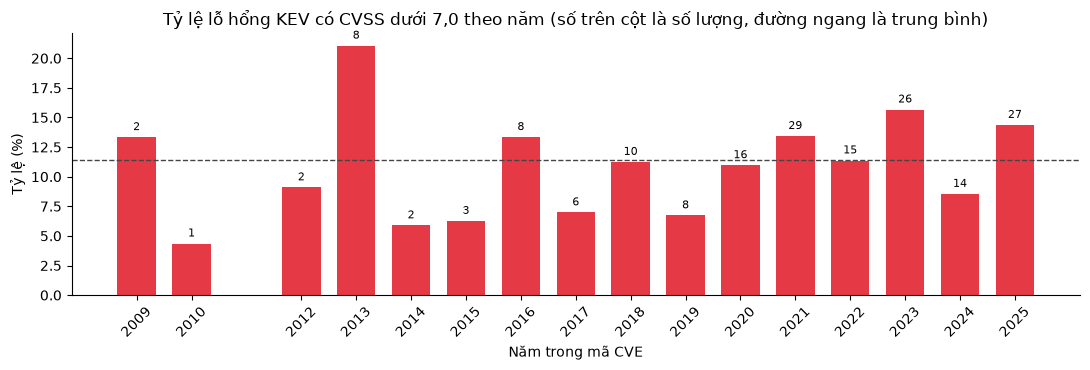

,so_kev,duoi_7,ty_le
nam,,,
2014,34,2,5.882353
2015,48,3,6.250000
2016,60,8,13.333333
2017,86,6,6.976744
2018,89,10,11.235955
2019,119,8,6.722689
2020,146,16,10.958904
2021,216,29,13.425926
2022,132,15,11.363636


In [6]:
ty = (k.groupby("nam").agg(so_kev=("cve", "size"), duoi_7=("cvss", lambda s: (s < CVSS_NGUONG).sum())))
ty["ty_le"] = 100 * ty["duoi_7"] / ty["so_kev"]
ty_ve = ty[ty["so_kev"] >= 10]

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(ty_ve.index, ty_ve["ty_le"], color="#e63946", width=0.7)
for x, (p, n) in zip(ty_ve.index, zip(ty_ve["ty_le"], ty_ve["duoi_7"])):
    ax.text(x, p + 0.6, f"{n}", ha="center", fontsize=8)
ax.axhline(100 * len(thap) / len(k), color="#444", ls="--", lw=1)
ax.set_xticks(ty_ve.index); ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Tỷ lệ (%)"); ax.set_xlabel("Năm trong mã CVE")
ax.set_title("Tỷ lệ lỗ hổng KEV có CVSS dưới 7,0 theo năm (số trên cột là số lượng, đường ngang là trung bình)")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig("kev_cvss_duoi_7_theo_nam.png", dpi=170); plt.show()
ty.tail(12)

## 7. Ví dụ các lỗ hổng đang bị khai thác nhưng có điểm CVSS thấp

In [7]:
vd = (thap.merge(kev[["cveID", "vendorProject", "product", "dateAdded"]], left_on="cve", right_on="cveID")
        .sort_values("cvss")[["cve", "cvss", "phien_ban", "vendorProject", "product", "dateAdded"]])
print(f"Cac nha cung cap xuat hien nhieu nhat trong nhom KEV co CVSS duoi {CVSS_NGUONG}:")
print(vd["vendorProject"].value_counts().head(8).to_string())
vd.head(15)

Cac nha cung cap xuat hien nhieu nhat trong nhom KEV co CVSS duoi 7.0:
vendorProject
Microsoft    36
Cisco        17
Apple        15
Samsung       8
Synacor       8
Roundcube     6
Google        6
VMware        5


,cve,cvss,phien_ban,vendorProject,product,dateAdded
151,CVE-2024-55550,2.7,3.x,Mitel,MiCollab,2025-01-07
114,CVE-2023-26083,3.3,3.x,Arm,Mali Graphics Processing Unit (GPU),2023-04-07
7,CVE-2013-0431,3.7,3.x,Oracle,Java Runtime Environment (JRE),2022-05-25
8,CVE-2013-2423,3.7,3.x,Oracle,Java Runtime Environment (JRE),2022-05-25
117,CVE-2023-20867,3.9,3.x,VMware,Tools,2023-06-23
164,CVE-2025-48928,4.0,3.x,TeleMessage,TM SGNL,2025-07-01
63,CVE-2020-0878,4.2,3.x,Microsoft,Edge and Internet Explorer,2021-11-03
166,CVE-2025-43200,4.2,3.x,Apple,Multiple Products,2025-06-16
21,CVE-2016-0162,4.3,3.x,Microsoft,Internet Explorer,2022-05-24
39,CVE-2018-13374,4.3,3.x,Fortinet,FortiOS and FortiADC,2022-09-08


## 8. Bảng tổng hợp cho báo cáo

Để so sánh công bằng, các bảng dưới đây chỉ dùng lỗ hổng có điểm **CVSS 3.x**, vì mọi lỗ hổng trong KEV đều có điểm 3.x.

In [8]:
co3 = df[df["phien_ban"] == "3.x"]
k3 = co3[co3["kev"]]
b = pd.DataFrame({
    "Tat ca lo hong": pd.cut(co3["cvss"], bins, labels=labels, right=False).value_counts().reindex(labels),
    "Lo hong KEV": pd.cut(k3["cvss"], bins, labels=labels, right=False).value_counts().reindex(labels)})
b["% trong tat ca"] = (100 * b["Tat ca lo hong"] / b["Tat ca lo hong"].sum()).round(1)
b["% trong KEV"] = (100 * b["Lo hong KEV"] / b["Lo hong KEV"].sum()).round(1)
b["Ty le bi khai thac (%)"] = (100 * b["Lo hong KEV"] / b["Tat ca lo hong"]).round(3)
print("BANG 1. Phan bo diem CVSS 3.x: tat ca lo hong so voi lo hong KEV")
display(b) if "display" in dir() else print(b)

print("\nBANG 2. Neu chi va theo nguong CVSS")
rows = []
for t in [7.0, 8.0, 9.0]:
    rows.append({"Nguong": f"CVSS tu {t}",
                 "Phai va (% tat ca lo hong)": round(100 * (co3["cvss"] >= t).mean(), 1),
                 "Lo hong KEV bi bo sot": int((k3["cvss"] < t).sum()),
                 "% KEV bi bo sot": round(100 * (k3["cvss"] < t).mean(), 1)})
b2 = pd.DataFrame(rows)
display(b2) if "display" in dir() else print(b2)

nam_kev = kev["cveID"].str.split("-").str[1].astype(int)
print(f"\nGhi chu: KEV co {len(kev):,} lo hong; {int((nam_kev > END_YEAR).sum())} lo hong co ma nam sau {END_YEAR} "
      f"nen khong nam trong pham vi; {len(kev) - len(k) - int((nam_kev > END_YEAR).sum())} lo hong con lai khong co diem CVSS tren NVD.")

BANG 1. Phan bo diem CVSS 3.x: tat ca lo hong so voi lo hong KEV
             Tat ca lo hong  Lo hong KEV  % trong tat ca  % trong KEV  \
cvss                                                                    
duoi 4.0               4785            5             2.0          0.3   
4.0 den 6.9          104999          174            43.7         11.1   
7.0 den 8.9           95928          857            39.9         54.6   
9.0 den 10            34697          534            14.4         34.0   

             Ty le bi khai thac (%)  
cvss                                 
duoi 4.0                      0.104  
4.0 den 6.9                   0.166  
7.0 den 8.9                   0.893  
9.0 den 10                    1.539  

BANG 2. Neu chi va theo nguong CVSS
        Nguong  Phai va (% tat ca lo hong)  Lo hong KEV bi bo sot  \
0  CVSS tu 7.0                        54.3                    179   
1  CVSS tu 8.0                        27.8                    693   
2  CVSS tu 9.0          

## 9. Thống kê theo ngưỡng 8,0 của CSA

Bài báo của Cloud Security Alliance khuyến nghị vá trong 48 giờ mọi lỗ hổng có CVSS từ 8,0 trở lên. Bảng dưới chia lỗ hổng thành bốn nhóm theo hai câu hỏi: có thuộc diện ưu tiên (CVSS từ 8,0) không, và có thực sự bị khai thác (nằm trong KEV) không. Chỉ dùng lỗ hổng có CVSS 3.x.

In [9]:
def ty_le(a, b):
    """Hien thi ro tu so va mau so, vi du: 877 / 1,570 = 55.86%"""
    return f"{a:,} / {b:,} = {100*a/b:.2f}%"

def bang_nguong(x, nguong=8.0):
    N, K = len(x), int(x["kev"].sum()); khong_kev = N - K
    cao = x["cvss"] >= nguong
    a = int((cao & x["kev"]).sum()); b = int((cao & ~x["kev"]).sum())
    c = int((~cao & x["kev"]).sum()); e = int((~cao & ~x["kev"]).sum())
    t = pd.DataFrame([
        ["CVSS tu 8.0, nam trong KEV (va dung)", a, ty_le(a, N), ty_le(a, K), "", ty_le(a, a + b)],
        ["CVSS tu 8.0, khong nam trong KEV", b, ty_le(b, N), "", ty_le(b, khong_kev), ty_le(b, a + b)],
        ["CVSS duoi 8.0, nam trong KEV (bi bo sot)", c, ty_le(c, N), ty_le(c, K), "", ty_le(c, c + e)],
        ["CVSS duoi 8.0, khong nam trong KEV", e, ty_le(e, N), "", ty_le(e, khong_kev), ty_le(e, c + e)]],
        columns=["Nhom", "So luong", "So voi tong so lo hong", "So voi nhom KEV",
                 "So voi nhom khong KEV", "So voi nhom cung nguong"])
    nhom = pd.DataFrame([
        ["Nhom CVSS tu 8.0 (phai va)", a + b, ty_le(a + b, N)],
        ["Nhom CVSS duoi 8.0", c + e, ty_le(c + e, N)],
        ["Nam trong KEV", K, ty_le(K, N)],
        ["Khong nam trong KEV", khong_kev, ty_le(khong_kev, N)]],
        columns=["Nhom", "So luong", "So voi tong so lo hong"])
    return t, nhom

co3 = df[df["phien_ban"] == "3.x"]
for ten, x in [("1999 den 2025", co3), ("2023 den 2025", co3[co3["nam"].between(2023, 2025)])]:
    print(f"\nGIAI DOAN {ten}: {len(x):,} lo hong, {int(x['kev'].sum()):,} lo hong KEV")
    t, nhom = bang_nguong(x)
    for bang in (nhom, t):
        display(bang) if "display" in dir() else print(bang.to_string(index=False))


GIAI DOAN 1999 den 2025: 240,409 lo hong, 1,570 lo hong KEV
                      Nhom  So luong     So voi tong so lo hong
Nhom CVSS tu 8.0 (phai va)     66722  66,722 / 240,409 = 27.75%
        Nhom CVSS duoi 8.0    173687 173,687 / 240,409 = 72.25%
             Nam trong KEV      1570    1,570 / 240,409 = 0.65%
       Khong nam trong KEV    238839 238,839 / 240,409 = 99.35%
                                    Nhom  So luong     So voi tong so lo hong      So voi nhom KEV      So voi nhom khong KEV    So voi nhom cung nguong
    CVSS tu 8.0, nam trong KEV (va dung)       877      877 / 240,409 = 0.36% 877 / 1,570 = 55.86%                                  877 / 66,722 = 1.31%
        CVSS tu 8.0, khong nam trong KEV     65845  65,845 / 240,409 = 27.39%                       65,845 / 238,839 = 27.57%   65,845 / 66,722 = 98.69%
CVSS duoi 8.0, nam trong KEV (bi bo sot)       693      693 / 240,409 = 0.29% 693 / 1,570 = 44.14%                                 693 / 173,687 = 0.40%
      C

## 10. Lưu kết quả

In [10]:
df.to_csv("cvss_kev_tat_ca.csv", index=False)
vd.to_csv("kev_cvss_duoi_7.csv", index=False)
print("Da luu: kev_cvss_theo_nam.png, kev_cvss_duoi_7_theo_nam.png, cvss_kev_tat_ca.csv, kev_cvss_duoi_7.csv")

Da luu: kev_cvss_theo_nam.png, kev_cvss_duoi_7_theo_nam.png, cvss_kev_tat_ca.csv, kev_cvss_duoi_7.csv
